Importujemy biblioteki potrzebne do wczytania danych, przygotowania par LR/HR i wyświetlenia obrazów.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from datasets import Dataset as HFDataset, load_from_disk
from PIL import Image
from torch import Tensor, nn
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import functional as TF

Ustawiamy ścieżkę do danych, skalowanie ×2, wielkość partii oraz limit treningu, który można wyłączyć przez ustawienie TRAIN_LIMIT na None.

In [2]:
SEED = 42
SCALE_FACTOR = 2
HR_SIZE = 256
BATCH_SIZE = 16
TRAIN_LIMIT = 2000
NUM_WORKERS = 0

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "notebooks" / "matg" / "dataloading_demo.py").is_file()
)
DATASET_PATH = (
    project_root / "notebooks" / "igoh" / "data" / "wikiart_train_processed"
)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if SCALE_FACTOR not in (2, 4) or HR_SIZE % SCALE_FACTOR != 0:
    raise ValueError("Wybierz skalowanie ×2 lub ×4 i podzielny rozmiar HR.")

LR_SIZE = HR_SIZE // SCALE_FACTOR
print(f"Dane: {DATASET_PATH}")
print(f"Urządzenie: {DEVICE}; LR: {LR_SIZE}×{LR_SIZE}; HR: {HR_SIZE}×{HR_SIZE}")

Dane: c:\Users\igorh\Desktop\VS 2022 files\image-inpainting-and-super-resolution\notebooks\igoh\data\wikiart_train_processed
Urządzenie: cuda; LR: 128×128; HR: 256×256


Wczytujemy lokalny zbiór WikiArt po preprocessingu i sprawdzamy, czy zawiera kolumnę z obrazami.

In [3]:
def load_wikiart(path: Path) -> HFDataset:
    """Wczytaj lokalny zbiór po preprocessingu, zachowując kolejność rekordów."""
    if not (path / "dataset_info.json").is_file():
        raise FileNotFoundError(f"Brak przygotowanego zbioru: {path}")
    dataset = load_from_disk(str(path))
    if not isinstance(dataset, HFDataset):
        raise TypeError("Oczekiwano pojedynczego Dataset, a nie słownika zbiorów.")
    if "image" not in dataset.column_names:
        raise ValueError("W zbiorze brakuje kolumny image.")
    return dataset


ds_full = load_wikiart(DATASET_PATH)
print(ds_full)

Dataset({
    features: ['title', 'artist', 'date', 'genre', 'style', 'filename', 'image'],
    num_rows: 102902
})


Dzielimy pełną bazę na trening, walidację i test zgodnie z konwencją, a następnie ograniczamy wyłącznie część treningową do wybranego limitu.

In [4]:
def split_wikiart(
    dataset: HFDataset, seed: int = SEED
) -> tuple[HFDataset, HFDataset, HFDataset]:
    """Odtwórz podział 80/10/10 stosowany w części projektu matg."""
    split = dataset.train_test_split(test_size=0.2, seed=seed)
    holdout = split["test"].train_test_split(test_size=0.5, seed=seed)
    return split["train"], holdout["train"], holdout["test"]


ds_train, ds_val, ds_test = split_wikiart(ds_full)
if TRAIN_LIMIT is not None and TRAIN_LIMIT <= 0:
    raise ValueError("TRAIN_LIMIT musi być dodatni albo równy None.")

# podział treningowy jest już losowy; wybieramy jego pierwsze rekordy
train_count = len(ds_train) if TRAIN_LIMIT is None else min(TRAIN_LIMIT, len(ds_train))
ds_train_used = ds_train.select(range(train_count))

print(f"Pełny podział: train={len(ds_train)}, val={len(ds_val)}, test={len(ds_test)}")
print(f"Trening użyty w eksperymencie: {len(ds_train_used)}")
assert len(ds_train) + len(ds_val) + len(ds_test) == len(ds_full)

Pełny podział: train=82321, val=10290, test=10291
Trening użyty w eksperymencie: 2000


Przygotowujemy pary tensorów RGB w zakresie [0, 1], pomniejszając oryginalny obraz HR do wejścia LR interpolacją bicubic.

In [5]:
class SuperResolutionDataset(Dataset[tuple[Tensor, Tensor]]):
    """Twórz pomniejszone wejście LR i referencję HR z tego samego obrazu."""

    def __init__(self, images: HFDataset, hr_size: int, scale_factor: int) -> None:
        """Zachowaj źródło i rozmiary par bez kopiowania obrazów."""
        if scale_factor <= 1 or hr_size <= 0 or hr_size % scale_factor != 0:
            raise ValueError("Niepoprawny rozmiar HR lub współczynnik skali.")
        self.images = images.select_columns(["image"])
        self.hr_size = hr_size
        self.lr_size = hr_size // scale_factor

    def __len__(self) -> int:
        """Zwróć liczbę dostępnych par."""
        return len(self.images)

    def __getitem__(self, index: int) -> tuple[Tensor, Tensor]:
        """Zdekoduj obraz i pomniejsz go bicubic, zachowując oryginał jako HR."""
        hr_image = self.images[index]["image"].convert("RGB")
        if hr_image.size != (self.hr_size, self.hr_size):
            raise ValueError(f"Obraz {index}: rozmiar {hr_image.size}, oczekiwano {self.hr_size}×{self.hr_size}.")
        lr_image = hr_image.resize(
            (self.lr_size, self.lr_size), resample=Image.Resampling.BICUBIC
        )
        return TF.to_tensor(lr_image), TF.to_tensor(hr_image)

Tworzymy DataLoadery dla wszystkich części zbioru, losując kolejność obrazów wyłącznie podczas treningu.

In [6]:
def make_loader(images: HFDataset, shuffle: bool) -> DataLoader:
    """Przygotuj partie par LR/HR; losuj kolejność wyłącznie dla treningu."""
    pairs = SuperResolutionDataset(images, HR_SIZE, SCALE_FACTOR)
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(
        pairs,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type == "cuda",
        generator=generator,
    )


train_loader = make_loader(ds_train_used, shuffle=True)
val_loader = make_loader(ds_val, shuffle=False)
test_loader = make_loader(ds_test, shuffle=False)

for name, loader in (("train", train_loader), ("val", val_loader), ("test", test_loader)):
    print(f"{name}: {len(loader)} partii")

train: 125 partii
val: 644 partii
test: 644 partii


Sprawdzamy rozmiary i wartości tensorów oraz porównujemy obraz LR, jego powiększenie bicubic i oryginalny obraz HR.

LR: (16, 3, 128, 128); HR: (16, 3, 256, 256)


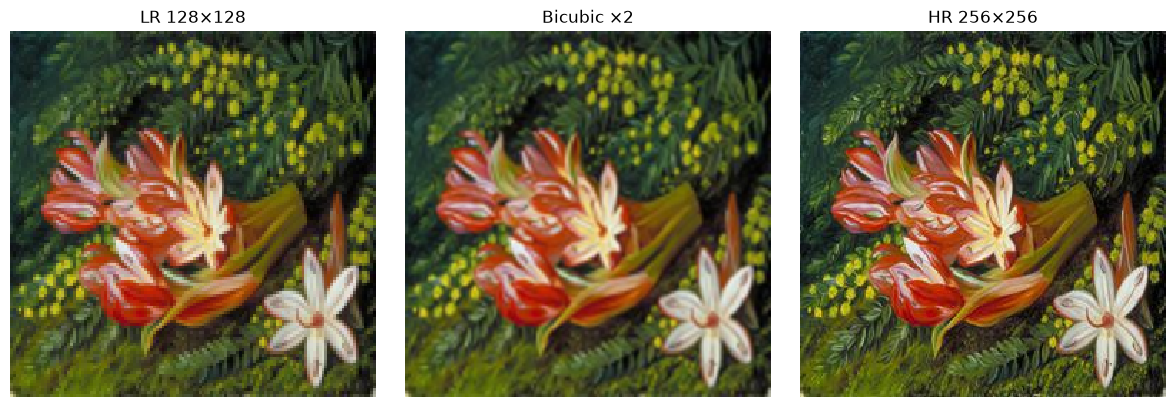

In [7]:
lr_batch, hr_batch = next(iter(val_loader))
assert lr_batch.shape[1:] == (3, LR_SIZE, LR_SIZE)
assert hr_batch.shape[1:] == (3, HR_SIZE, HR_SIZE)
for batch in (lr_batch, hr_batch):
    assert batch.dtype == torch.float32
    assert torch.isfinite(batch).all()
    assert 0.0 <= batch.min().item() <= batch.max().item() <= 1.0

print(f"LR: {tuple(lr_batch.shape)}; HR: {tuple(hr_batch.shape)}")

lr_image = TF.to_pil_image(lr_batch[0])
bicubic_image = lr_image.resize((HR_SIZE, HR_SIZE), Image.Resampling.BICUBIC)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
previews = (
    (lr_image, f"LR {LR_SIZE}×{LR_SIZE}"),
    (bicubic_image, f"Bicubic ×{SCALE_FACTOR}"),
    (TF.to_pil_image(hr_batch[0]), f"HR {HR_SIZE}×{HR_SIZE}"),
)
for axis, (image, title) in zip(axes, previews):
    axis.imshow(image, interpolation="nearest")
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

Budujemy ESPCN, który przetwarza obraz LR warstwami konwolucyjnymi i za pomocą PixelShuffle zamienia 12 kanałów na obraz RGB o dwukrotnie większych wymiarach przy skali ×2.

In [8]:
class ESPCN(nn.Module):
    """Zwiększaj rozdzielczość RGB, ucząc cechy przed powiększeniem obrazu."""

    def __init__(self, scale_factor: int = 2) -> None:
        """Zbuduj trzy konwolucje oraz warstwę przestawiającą kanały w piksele."""
        super().__init__()
        if scale_factor not in (2, 4):
            raise ValueError("Obsługiwane skale to ×2 i ×4.")
        self.layers = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 3 * scale_factor ** 2, kernel_size=3, padding=1),
            nn.PixelShuffle(scale_factor),
        )

    def forward(self, lr: Tensor) -> Tensor:
        """Przekształć partię LR (N, 3, H, W) w SR (N, 3, skala·H, skala·W)."""
        return self.layers(lr)


Przepuszczamy jedną partię walidacyjną przez niewytrenowany model i sprawdzamy kształt wyniku, którego wartości nie muszą jeszcze należeć do zakresu [0, 1].

In [9]:
torch.manual_seed(SEED)
model = ESPCN(scale_factor=SCALE_FACTOR).to(DEVICE)
model.eval()

with torch.inference_mode():
    sr_batch = model(lr_batch.to(DEVICE)).cpu()

assert sr_batch.shape == hr_batch.shape
assert torch.isfinite(sr_batch).all()
print(model)
print(f"Wejście LR: {tuple(lr_batch.shape)}")
print(f"Wynik SR:   {tuple(sr_batch.shape)}")
print(f"Cel HR:     {tuple(hr_batch.shape)}")


ESPCN(
  (layers): Sequential(
    (0): Conv2d(3, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): ReLU()
    (2): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): PixelShuffle(upscale_factor=2)
  )
)
Wejście LR: (16, 3, 128, 128)
Wynik SR:   (16, 3, 256, 256)
Cel HR:     (16, 3, 256, 256)


Porównujemy MSE niewytrenowanego modelu i interpolacji bicubic względem HR na tej samej partii walidacyjnej, bez zmieniania wag modelu.

In [10]:
criterion = nn.MSELoss()

bicubic_batch = torch.stack([
    TF.to_tensor(
        TF.to_pil_image(image).resize(
            (HR_SIZE, HR_SIZE), resample=Image.Resampling.BICUBIC
        )
    )
    for image in lr_batch
])

model_mse = criterion(sr_batch, hr_batch).item()
bicubic_mse = criterion(bicubic_batch, hr_batch).item()

print(f"MSE modelu:  {model_mse:.6f}")
print(f"MSE bicubic: {bicubic_mse:.6f}")


MSE modelu:  0.330852
MSE bicubic: 0.001704


Tworzymy optymalizator Adam z krokiem uczenia 0,001, uruchamiając tę komórkę raz przed kolejnymi aktualizacjami wag.

In [11]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


Wykonujemy jeden krok uczenia na partii treningowej i porównujemy jej MSE przed aktualizacją wag oraz po niej, pamiętając, że ponowne uruchomienie tej komórki wykona kolejny krok.

In [12]:
train_lr, train_hr = next(iter(train_loader))
train_lr = train_lr.to(DEVICE)
train_hr = train_hr.to(DEVICE)

model.train()
optimizer.zero_grad()
train_sr = model(train_lr)
loss = criterion(train_sr, train_hr)
mse_before = loss.item()

loss.backward()
optimizer.step()

model.eval()
with torch.no_grad():
    train_sr_after = model(train_lr)
    mse_after = criterion(train_sr_after, train_hr).item()

print(f"MSE przed krokiem: {mse_before:.6f}")
print(f"MSE po kroku:     {mse_after:.6f}")


MSE przed krokiem: 0.390243
MSE po kroku:     0.336370


Definiujemy trening jednej epoki, który aktualizuje wagi dla każdej partii i zwraca średnie MSE ważone liczbą obrazów w partiach.

In [13]:
def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.MSELoss,
    optimizer: torch.optim.Optimizer,
    device: torch.device,
) -> float:
    """Przejdź raz przez trening i zwróć średnią stratę na przetworzony obraz."""
    model.train()
    total_loss = 0.0
    image_count = 0

    for lr, hr in loader:
        lr = lr.to(device)
        hr = hr.to(device)
        optimizer.zero_grad()
        sr = model(lr)
        loss = criterion(sr, hr)
        loss.backward()
        optimizer.step()

        batch_size = lr.shape[0]
        total_loss += loss.item() * batch_size
        image_count += batch_size

    if image_count == 0:
        raise ValueError("Brak obrazów do treningu.")
    return total_loss / image_count


Uruchamiamy jedną epokę na całym train_loader, kontynuując uczenie po wcześniejszym pojedynczym kroku, i wypisujemy średnie MSE z jej przebiegu.

In [14]:
train_mse = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
print(f"Średnie MSE treningowe po przebiegu jednej epoki: {train_mse:.6f}")


Średnie MSE treningowe po przebiegu jednej epoki: 0.019194


Definiujemy walidację, która ocenia model na całym podzbiorze walidacyjnym bez obliczania gradientów i zmieniania wag, zwracając średnie MSE ważone liczbą obrazów.

In [15]:
@torch.no_grad()
def validate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.MSELoss,
    device: torch.device,
) -> float:
    """Oceń bieżące wagi na danych walidacyjnych i zwróć średnie MSE na obraz."""
    model.eval()
    total_loss = 0.0
    image_count = 0

    for lr, hr in loader:
        lr = lr.to(device)
        hr = hr.to(device)
        sr = model(lr)
        loss = criterion(sr, hr)

        batch_size = lr.shape[0]
        total_loss += loss.item() * batch_size
        image_count += batch_size

    if image_count == 0:
        raise ValueError("Brak obrazów do walidacji.")
    return total_loss / image_count


Obliczamy MSE walidacyjne dla wag po jednej epoce, pamiętając, że wcześniejsze MSE treningowe było średnią z przebiegu uczenia przy zmieniających się wagach.

In [16]:
val_mse = validate(model, val_loader, criterion, DEVICE)
print(f"Średnie MSE z przebiegu treningu: {train_mse:.6f}")
print(f"MSE walidacyjne po epoce:        {val_mse:.6f}")


Średnie MSE z przebiegu treningu: 0.019194
MSE walidacyjne po epoce:        0.004244


Obliczamy średnie MSE bicubic na całej walidacji, używając tej samej interpolacji Pillow co we wcześniejszym porównaniu jednej partii.

In [17]:
@torch.no_grad()
def validate_bicubic(loader: DataLoader, criterion: nn.MSELoss) -> float:
    """Porównaj powiększone obrazy LR z HR i zwróć średnie MSE na obraz."""
    total_loss = 0.0
    image_count = 0

    for lr, hr in loader:
        target_size = (hr.shape[-1], hr.shape[-2])
        bicubic = torch.stack([
            TF.to_tensor(
                TF.to_pil_image(image).resize(
                    target_size, resample=Image.Resampling.BICUBIC
                )
            )
            for image in lr
        ])
        loss = criterion(bicubic, hr)
        batch_size = lr.shape[0]
        total_loss += loss.item() * batch_size
        image_count += batch_size

    if image_count == 0:
        raise ValueError("Brak obrazów do oceny bicubic.")
    return total_loss / image_count


Porównujemy MSE modelu po jednej epoce z MSE bicubic na tych samych obrazach walidacyjnych, gdzie niższa wartość oznacza lepsze dopasowanie do HR.

In [18]:
bicubic_val_mse = validate_bicubic(val_loader, criterion)
print(f"MSE modelu na walidacji:  {val_mse:.6f}")
print(f"MSE bicubic na walidacji: {bicubic_val_mse:.6f}")

if val_mse < bicubic_val_mse:
    print("Model uzyskał niższe MSE niż bicubic.")
elif val_mse > bicubic_val_mse:
    print("Bicubic uzyskało niższe MSE niż model.")
else:
    print("Model i bicubic uzyskały takie samo MSE.")


MSE modelu na walidacji:  0.004244
MSE bicubic na walidacji: 0.001793
Bicubic uzyskało niższe MSE niż model.


Porównujemy LR, bicubic, wynik aktualnego modelu i HR dla trzech obrazów walidacyjnych, ograniczając wartości wyniku do [0, 1] wyłącznie na potrzeby wyświetlania.

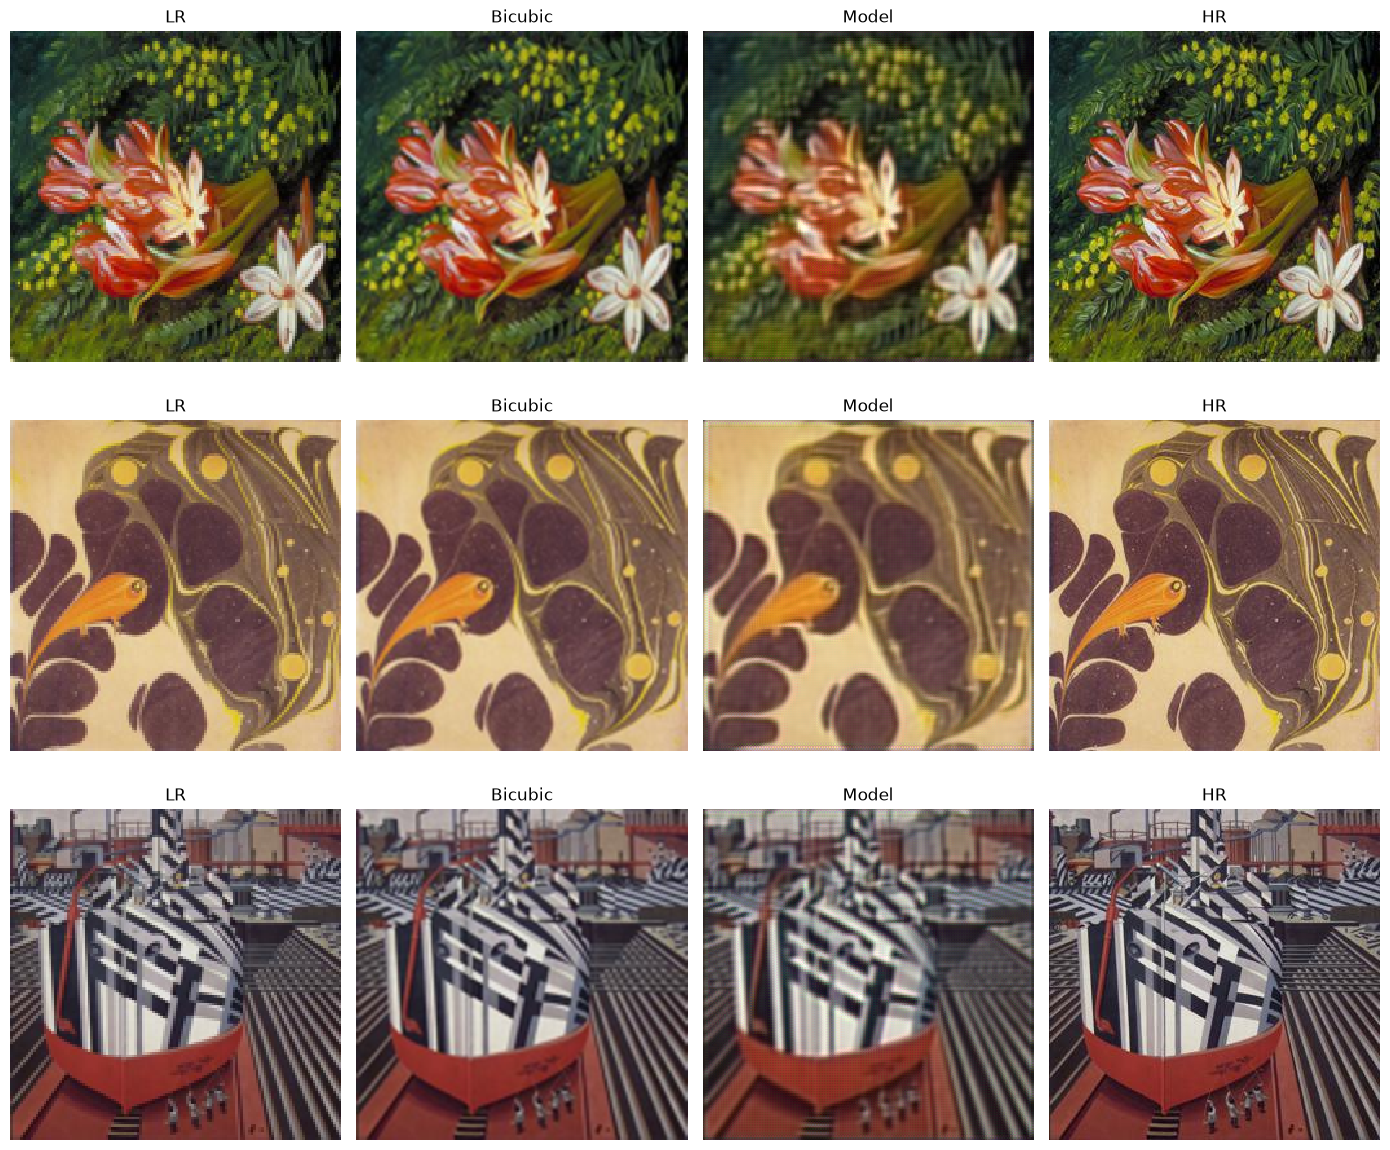

In [19]:
preview_lr, preview_hr = next(iter(val_loader))
preview_lr = preview_lr[:3]
preview_hr = preview_hr[:3]
model.eval()
with torch.no_grad():
    preview_sr = model(preview_lr.to(DEVICE)).cpu()

fig, axes = plt.subplots(len(preview_lr), 4, figsize=(14, 4 * len(preview_lr)), squeeze=False)
for row in range(len(preview_lr)):
    lr_image = TF.to_pil_image(preview_lr[row])
    target_size = (preview_hr.shape[-1], preview_hr.shape[-2])
    bicubic_image = lr_image.resize(target_size, Image.Resampling.BICUBIC)
    images = (
        (lr_image, "LR"),
        (bicubic_image, "Bicubic"),
        (TF.to_pil_image(preview_sr[row].clamp(0, 1)), "Model"),
        (TF.to_pil_image(preview_hr[row]), "HR"),
    )
    for axis, (image, title) in zip(axes[row], images):
        axis.imshow(image, interpolation="nearest")
        axis.set_title(title)
        axis.axis("off")

plt.tight_layout()
plt.show()


Rozpoczynamy historię od wyników pierwszej epoki i ustawiamy pięć dodatkowych epok, uruchamiając tę komórkę raz przed kontynuowaniem treningu.

In [20]:
ADDITIONAL_EPOCHS = 5
train_history = [train_mse]
val_history = [val_mse]


Kontynuujemy trening z obecnymi wagami i optymalizatorem przez pięć epok, zapisując MSE treningowe i walidacyjne po każdej z nich bez ponownego liczenia bicubic.

In [21]:
for _ in range(ADDITIONAL_EPOCHS):
    epoch = len(train_history) + 1
    train_mse = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_mse = validate(model, val_loader, criterion, DEVICE)
    train_history.append(train_mse)
    val_history.append(val_mse)
    print(
        f"Epoka {epoch}: train MSE = {train_mse:.6f}, "
        f"val MSE = {val_mse:.6f}"
    )


Epoka 2: train MSE = 0.003213, val MSE = 0.002637
Epoka 3: train MSE = 0.002250, val MSE = 0.002004
Epoka 4: train MSE = 0.001905, val MSE = 0.001841
Epoka 5: train MSE = 0.001735, val MSE = 0.001737
Epoka 6: train MSE = 0.001733, val MSE = 0.001680


Rysujemy MSE z kolejnych epok oraz stały wynik bicubic na walidacji, pamiętając, że strata treningowa jest średnią z przebiegu uczenia przy zmieniających się wagach.

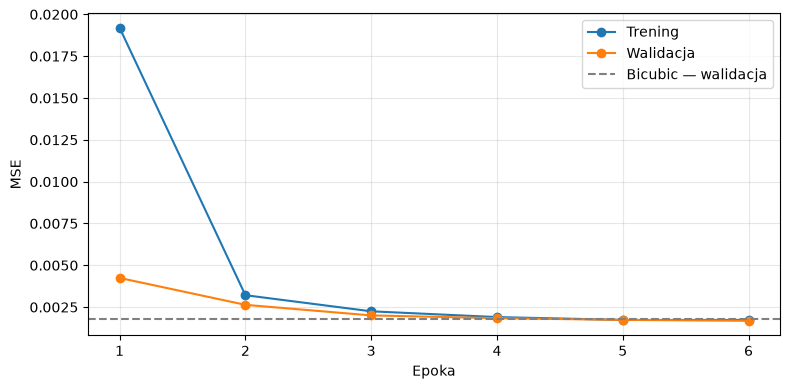

In [22]:
epochs = range(1, len(train_history) + 1)
fig, axis = plt.subplots(figsize=(8, 4))
axis.plot(epochs, train_history, marker="o", label="Trening")
axis.plot(epochs, val_history, marker="o", label="Walidacja")
axis.axhline(bicubic_val_mse, color="gray", linestyle="--", label="Bicubic — walidacja")
axis.set_xlabel("Epoka")
axis.set_ylabel("MSE")
axis.set_xticks(epochs)
axis.legend()
axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Porównujemy LR, bicubic, wynik modelu po ostatnim treningu i HR dla tych samych trzech obrazów walidacyjnych co wcześniej, ograniczając wartości wyniku do [0, 1] tylko podczas wyświetlania.

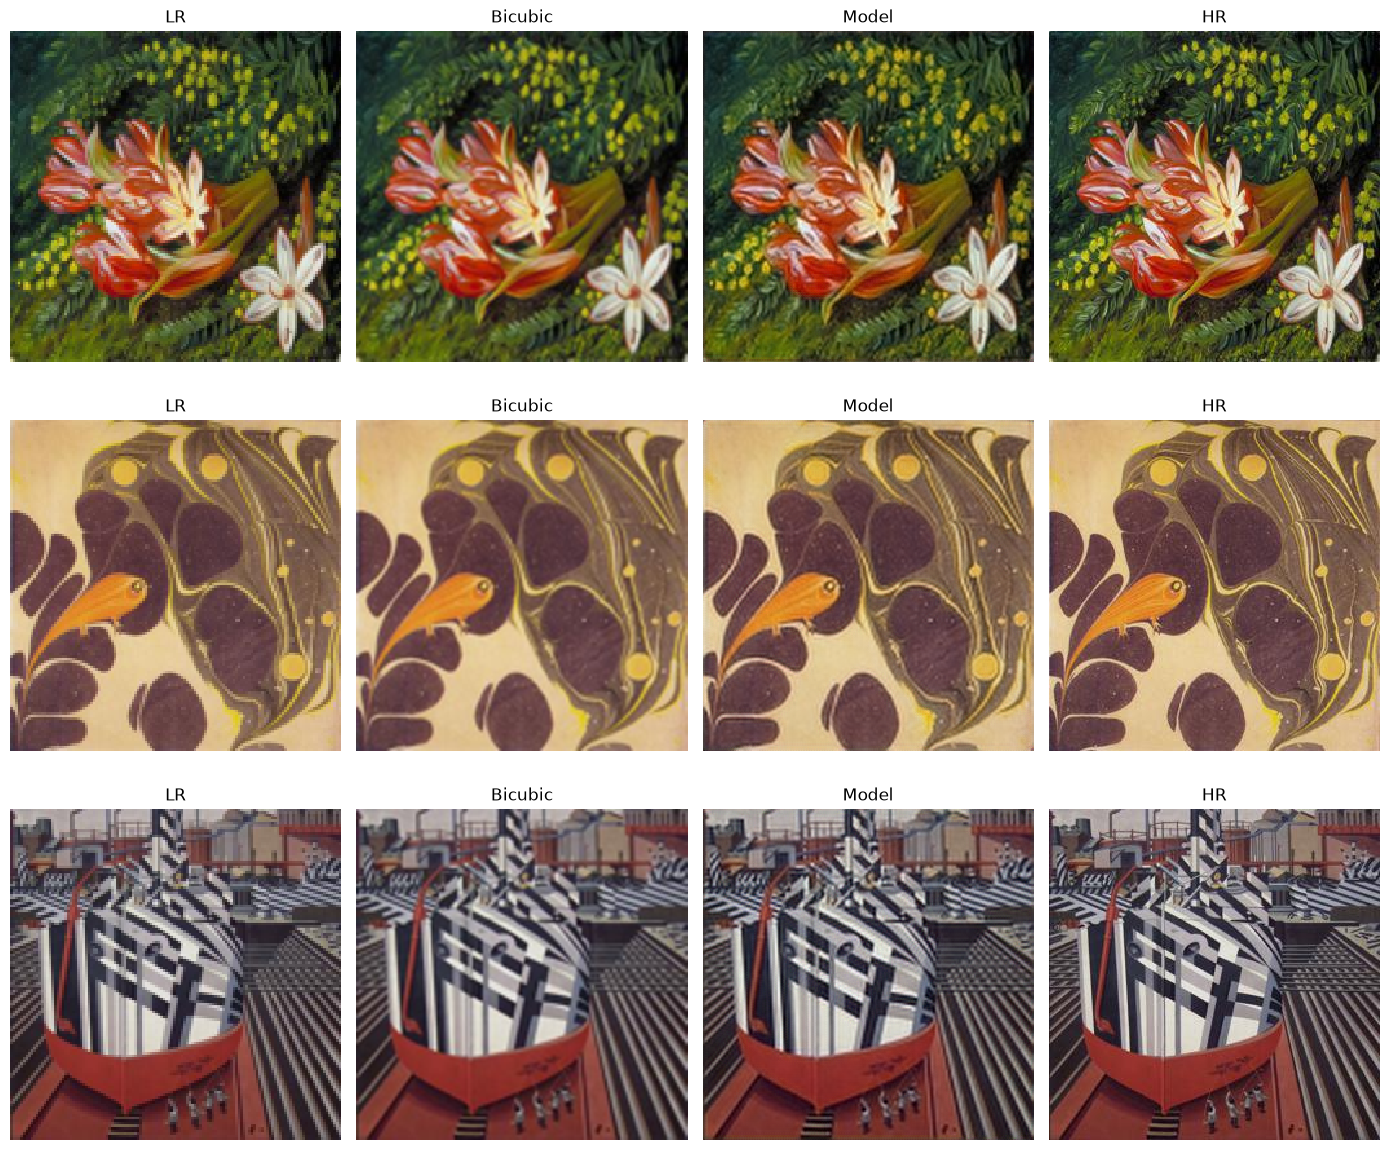

In [23]:
preview_lr, preview_hr = next(iter(val_loader))
preview_lr = preview_lr[:3]
preview_hr = preview_hr[:3]
model.eval()
with torch.no_grad():
    preview_sr = model(preview_lr.to(DEVICE)).cpu()

fig, axes = plt.subplots(len(preview_lr), 4, figsize=(14, 4 * len(preview_lr)), squeeze=False)
for row in range(len(preview_lr)):
    lr_image = TF.to_pil_image(preview_lr[row])
    target_size = (preview_hr.shape[-1], preview_hr.shape[-2])
    bicubic_image = lr_image.resize(target_size, Image.Resampling.BICUBIC)
    images = (
        (lr_image, "LR"),
        (bicubic_image, "Bicubic"),
        (TF.to_pil_image(preview_sr[row].clamp(0, 1)), "Model"),
        (TF.to_pil_image(preview_hr[row]), "HR"),
    )
    for axis, (image, title) in zip(axes[row], images):
        axis.imshow(image, interpolation="nearest")
        axis.set_title(title)
        axis.axis("off")

plt.tight_layout()
plt.show()
